<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Statsmodels Regression](https://github.com/Query-farm/vgi-statsmodels)

Regression fits and hypothesis tests over SQL relations.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-statsmodels/blob/main/notebooks/03_a_mean_shift_is_not_a_unit_root.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-statsmodels/blob/main/notebooks/README.md)


## 03 · A mean shift is not a unit-root diagnosis

A two-sample t-test asks whether two independent populations have equal means.
An Augmented Dickey-Fuller test asks about a unit root in an ordered series.
They return similar-looking statistics and p-values but use different null hypotheses
and different data assumptions. We keep their populations separate and reconstruct
the pooled t statistic in SQL before comparing two disclosed time-series generators.

**All inputs are synthetic.** The two independent batches are not repeated measurements
from the ordered traces; their row IDs do not pair them. No real device-quality or
scientific conclusion is being made.

### Move one batch without changing either time series

`BATCH_SHIFT` is **1.0 measurement unit**, with an experiment at **0.0** and an accepted
range 0–3. Seed 314 supplies 80 independent standard-normal errors for each batch.
Their means are generated as 10 (A) and `10+BATCH_SHIFT` (B).

A separate seed 1618 supplies 240 standard-normal innovations. One trace is that white
noise itself; the other is its cumulative sum, a random walk starting from zero before
the first innovation. Time is a sample index, not calendar time. Both traces and all
error draws remain fixed when the batch shift changes.

In [1]:
BATCH_SHIFT = 1.0  # Experiment: 0.0; measurement units.

### Run this notebook

Read the saved output on GitHub or use **Open in Colab**, then Run All. The shared
base package preserves compatible preloaded plotting/data libraries. Initial downloads
need internet; all analytical inputs are deterministic synthetic data created locally.
The short Git-tag launcher installs the released worker in its own environment, using
its declared Python requirement. No credentials, cloned source or local worker build
are required. Actual hosted Colab has not been tested; a fresh preloaded Python 3.12
notebook-only execution exercises this installation and worker launch path.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.24":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.24"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.24":
    raise RuntimeError("Install shared tools v0.3.24, then restart and run all.")

In [3]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

%matplotlib inline
theme()
session = connect(globals())
con = session.connection

if type(BATCH_SHIFT) not in {int, float} or not np.isfinite(BATCH_SHIFT) or not 0 <= BATCH_SHIFT <= 3:
    raise ValueError("BATCH_SHIFT must be a finite number from 0 to 3.")
batch_noise = pd.DataFrame({"row_id": np.arange(160), "noise": np.random.default_rng(314).normal(size=160)})
innovations = pd.DataFrame({"t": np.arange(240), "innovation": np.random.default_rng(1618).normal(size=240)})
fingerprint = hashlib.sha256(
    (
        batch_noise.to_json(orient="records", double_precision=15)
        + innovations.to_json(orient="records", double_precision=15)
    ).encode()
).hexdigest()
for table, frame in [("batch_noise", batch_noise), ("innovations", innovations)]:
    con.register("staging", frame)
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM staging")
    con.unregister("staging")
batches = tested = adf = traces = pd.DataFrame()

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'statsmodels' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-statsmodels@v0.4.0 vgi-statsmodels');

,Success


### Define the groups and the direction of subtraction

This released worker uses a **two-sided, equal-variance pooled t-test**, not Welch's
test. The two groups are independent and have the same error variance by construction;
those assumptions need justification for real data. The ordered input places A first,
so the returned `mean_diff` is **mean(A) − mean(B)**. Reversing group appearance would
reverse the statistic and mean difference, but not the two-sided p-value.

SQL quotes the `"column"` and `"group"` argument names because they are keywords.
Missing values are checked before calling the worker, so implicit dropping does not
change the comparison population.

In [5]:
%%sql
CREATE TABLE batches AS SELECT row_id,CASE WHEN row_id<80 THEN 'A' ELSE 'B' END AS batch,
 10+noise+CASE WHEN row_id>=80 THEN {{BATCH_SHIFT}} ELSE 0 END AS value FROM batch_noise;
CREATE TABLE batch_summary AS SELECT batch,count(*) AS n,avg(value) AS mean_value,var_samp(value) AS variance,
 count(*) FILTER(WHERE value IS NULL OR NOT isfinite(value)) AS unavailable FROM batches GROUP BY batch;
CREATE TABLE test_result AS SELECT * FROM statsmodels.main.ttest(
 (SELECT batch,value FROM batches ORDER BY batch,row_id),"column" := 'value',"group" := 'batch');
CREATE TABLE test_check AS
WITH paired AS (SELECT a.n AS na,b.n AS nb,a.mean_value-b.mean_value AS difference,
 ((a.n-1)*a.variance+(b.n-1)*b.variance)/(a.n+b.n-2) AS pooled_variance
 FROM batch_summary a CROSS JOIN batch_summary b WHERE a.batch='A' AND b.batch='B')
SELECT t.*,difference AS sql_mean_diff,na+nb-2 AS sql_df,
 sqrt(pooled_variance*(1.0/na+1.0/nb)) AS sql_standard_error,
 difference/sqrt(pooled_variance*(1.0/na+1.0/nb)) AS sql_statistic FROM paired CROSS JOIN test_result t;
SELECT * FROM test_check;

,statistic,p_value,df,mean_diff,sql_mean_diff,sql_df,sql_standard_error,sql_statistic
0,-4.854802,0.000003,158.0,-0.743999,-0.743999,158,0.15325,-4.854802


In [6]:
%%sql batches <<
SELECT * FROM batch_summary ORDER BY batch;

In [7]:
%%sql tested <<
SELECT * FROM test_check;

,batch,n,mean_value,variance,unavailable
0,A,80,10.046826,1.005044,0
1,B,80,10.790825,0.873805,0


,statistic,p_value,df,mean_diff,sql_mean_diff,sql_df,sql_standard_error,sql_statistic
0,-4.854802,0.000003,158.0,-0.743999,-0.743999,158,0.15325,-4.854802


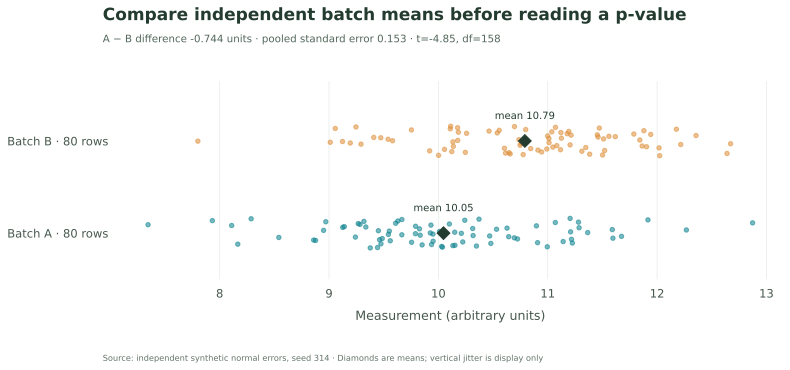

The observed A − B mean difference is **-0.744 units**, with pooled t=-4.855 and two-sided p=2.87e-06. SQL independently reproduces the difference, standard error, statistic and degrees of freedom. At 0.05 this rejects equal population means under the pooled-test assumptions. The p-value is not a probability that the null is true.

In [8]:
display(batches)
display(tested)
t = tested.iloc[0]
assert batches.n.tolist() == [80, 80] and batches.unavailable.sum() == 0
assert np.isclose(t.mean_diff, t.sql_mean_diff) and np.isclose(t.statistic, t.sql_statistic)
assert t.df == t.sql_df == 158 and 0 <= t.p_value <= 1
fig, ax = plt.subplots(figsize=(10.5, 5.4))
raw = con.execute("SELECT * FROM batches ORDER BY batch,row_id").fetchdf()
for i, batch in enumerate(["A", "B"]):
    values = raw.loc[raw.batch == batch, "value"].to_numpy()
    jitter = np.linspace(-0.16, 0.16, len(values))
    ax.scatter(values, i + jitter, color=["#087F8C", "#DC8C36"][i], alpha=0.55, s=20)
    ax.plot([values.mean()], [i], marker="D", ms=9, color="#243B2F")
    ax.annotate(
        f"mean {values.mean():.2f}",
        (values.mean(), i),
        xytext=(0, 22),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )
ax.set(
    yticks=[0, 1],
    yticklabels=["Batch A · 80 rows", "Batch B · 80 rows"],
    xlabel="Measurement (arbitrary units)",
    ylim=(-0.5, 1.65),
)
ax.grid(axis="x")
finish(
    fig,
    "Compare independent batch means before reading a p-value",
    f"A − B difference {t.mean_diff:+.3f} units · pooled standard error {t.sql_standard_error:.3f} · t={t.statistic:.2f}, df=158",
    "Source: independent synthetic normal errors, seed 314 · Diamonds are means; vertical jitter is display only",
    name=f"batch-means-{BATCH_SHIFT:g}",
)
prose(
    f"The observed A − B mean difference is **{t.mean_diff:+.3f} units**, with pooled t={t.statistic:.3f} and two-sided p={t.p_value:.3g}. SQL independently reproduces the difference, standard error, statistic and degrees of freedom. {'At 0.05 this rejects equal population means under the pooled-test assumptions.' if t.p_value < 0.05 else 'At 0.05 this does not reject equal means; it does not demonstrate equivalence.'} The p-value is not a probability that the null is true."
)

### Preserve order when asking a different question

The ADF null is a **unit root**, with an alternative of no unit root under the chosen
specification. This wrapper uses a constant, default maximum lag and AIC lag selection;
it does not expose a trend specification or return critical values. A failure to reject
is not proof of a unit root, and rejection alone is not a full diagnosis of stationarity.
These are raw constructed series, not regression residuals or a cointegration test.

The white-noise trace is the innovation itself. The random walk is its cumulative sum.
The explicit `ORDER BY t` inside each input subquery is essential: a SQL relation has
no inherent order. Materialization keeps each ADF call separate from display.

In [9]:
%%sql
CREATE TABLE series AS
SELECT t,innovation AS white_noise,sum(innovation) OVER(ORDER BY t ROWS UNBOUNDED PRECEDING) AS random_walk
FROM innovations;
CREATE TABLE adf_results AS
SELECT 'White noise' AS series,* FROM statsmodels.main.adfuller(
 (SELECT white_noise AS value FROM series ORDER BY t),"column" := 'value')
UNION ALL
SELECT 'Random walk',* FROM statsmodels.main.adfuller(
 (SELECT random_walk AS value FROM series ORDER BY t),"column" := 'value');
SELECT series,statistic,p_value,used_lag,n_obs FROM adf_results ORDER BY series;

,series,statistic,p_value,used_lag,n_obs
0,Random walk,-2.096769,2.458158e-01,0,239
1,White noise,-16.075019,5.455015e-29,0,239


In [10]:
%%sql adf <<
SELECT * FROM adf_results ORDER BY series;

In [11]:
%%sql traces <<
SELECT * FROM series ORDER BY t;

,series,statistic,p_value,used_lag,n_obs
0,Random walk,-2.096769,2.458158e-01,0,239
1,White noise,-16.075019,5.455015e-29,0,239


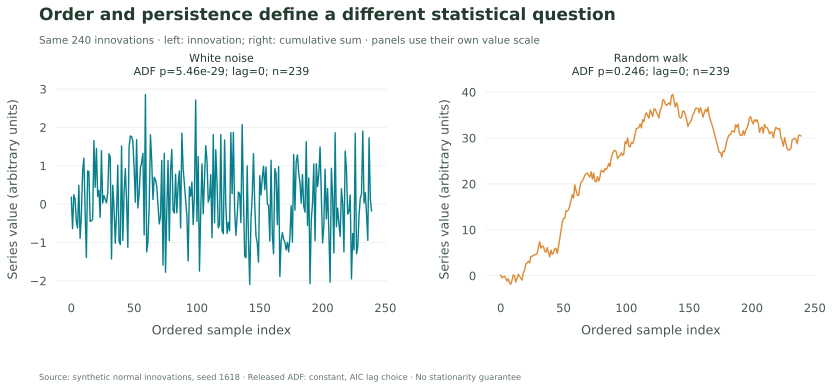

For these seeded samples, **Random walk: do not reject a unit root at 0.05 (p=0.246); White noise: reject a unit root at 0.05 (p=5.46e-29)**. These conclusions concern time-series persistence, not equality of the two independent batch means. No repeated-sampling power or size study is performed. Missing values and ordering were controlled explicitly before the worker saw the series.

27454

In [12]:
display(adf)
assert len(adf) == 2 and adf.p_value.between(0, 1).all()
assert (adf.n_obs == 240 - 1 - adf.used_lag).all()
assert len(traces) == 240 and traces.t.tolist() == list(range(240))
assert np.allclose(traces.random_walk, traces.white_noise.cumsum())
fig, axes = plt.subplots(1, 2, figsize=(12, 5.7))
for ax, label, column, color in zip(
    axes, ["White noise", "Random walk"], ["white_noise", "random_walk"], ["#087F8C", "#DC8C36"], strict=True
):
    row = adf.set_index("series").loc[label]
    ax.plot(traces.t, traces[column], color=color, lw=1.4)
    ax.set(xlabel="Ordered sample index", ylabel="Series value (arbitrary units)")
    ax.set_title(f"{label}\nADF p={row.p_value:.3g}; lag={int(row.used_lag)}; n={int(row.n_obs)}", fontsize=11, pad=10)
    ax.grid(axis="y")
finish(
    fig,
    "Order and persistence define a different statistical question",
    "Same 240 innovations · left: innovation; right: cumulative sum · panels use their own value scale",
    "Source: synthetic normal innovations, seed 1618 · Released ADF: constant, AIC lag choice · No stationarity guarantee",
    name=f"ordered-series-{BATCH_SHIFT:g}",
)
conclusions = "; ".join(
    f"{row.series}: {'reject' if row.p_value < 0.05 else 'do not reject'} a unit root at 0.05 (p={row.p_value:.3g})"
    for row in adf.itertuples()
)
prose(
    f"For these seeded samples, **{conclusions}**. These conclusions concern time-series persistence, not equality of the two independent batch means. No repeated-sampling power or size study is performed. Missing values and ordering were controlled explicitly before the worker saw the series."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/tests-audit.json").write_text(
    json.dumps(
        {
            "batch_shift": BATCH_SHIFT,
            "draw_fingerprint": fingerprint,
            "batches": batches.to_dict("records"),
            "ttest": tested.to_dict("records"),
            "adf": adf.to_dict("records"),
            "series": traces.to_dict("records"),
        },
        indent=2,
    )
)

### Experiment: remove the generated batch shift

Change only `BATCH_SHIFT` from **1.0 to 0.0**. The observed A − B difference should
increase by exactly one unit; its pooled standard error and degrees of freedom should
stay fixed. The t statistic and p-value can change. Neither ordered trace nor any ADF
result should change at all. Compare both figures and the fixed-draw fingerprint.

Use the question and sampling design to select a test, not whichever p-value happens
to be smallest. An equivalence claim needs a specified margin and a different test;
a time-series model needs more diagnostics than a single unit-root result. Primary
references: [pooled independent t-test](https://www.statsmodels.org/stable/generated/statsmodels.stats.weightstats.ttest_ind.html)
and [ADF options and null](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html).

In [13]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-statsmodels](https://github.com/Query-farm/vgi-statsmodels)